# Modes: the secular function, and counting instead of searching

The $\Omega d$ problem was first met in the search for modes. Dunkin's paper of 1965 is about the dispersion curves of surface waves on a layered elastic half-space, whose secular function is a determinant built from the transfer matrix, and it is to that determinant that he and Thrower applied the compound ("delta") matrix. This notebook does the optical version: guided modes of dielectric multilayer waveguides, with one channel and with two.

## What this notebook shows

- With one channel the secular function is $1/t$ and the rescaled vector of notebook 01 gives it to rounding, with or without thick layers. The search for its sign changes has a different weakness: two modes closer together than the search grid produce no sign change, and that is what a thick layer between two guides makes.
- With two channels the secular function from the transfer matrix is a $2\times2$ determinant, and it shows Dunkin's cancellation: its relative error is $\epsilon\,e^{(\kappa_1-\kappa_2)D}$ for a layer of thickness $D$ in which the two waves decay at different rates. In Plücker coordinates the same determinant is one of the six numbers carried, and is accurate at any thickness.
- Modes can be counted without being found. For a dielectric stack the number of modes with effective index above a given $\beta$ is the number of negative directions of a quadratic form, and the stiffness matrices of notebook 03 give it as the number of negative pivots of a block-tridiagonal matrix (the Wittrick-Williams algorithm of structural mechanics, which is the Sturm oscillation theorem in matrix form). The count is an integer, it uses decaying exponentials only, and bisection on it finds every mode with its multiplicity.
- Two coupled guides: the splitting of the pair of supermodes is followed down to the last bit of $\beta$, many decades below the point where a sign search on a fixed grid stops seeing two modes, and beyond that the count reports one mode of multiplicity two.
- Two guides coupled through a birefringent layer: the splitting of the hybrid supermodes is a difference of two exponentials, one for each evanescent wave of the layer, and it passes through zero at one thickness, where the even and odd supermodes cross.

## Conventions

As in the other notebooks. A guided mode is a solution that decays in both outer media, at real $\beta$ above their indices. All structures here are lossless dielectrics.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

# Figure style shared by every notebook in notebooks/omega_d (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib, warnings, time
sys.path.insert(0, str(pathlib.Path.cwd()))          # multilayer.py sits next to this notebook
import multilayer as ml
import mpmath as mp
from scipy.optimize import brentq

warnings.filterwarnings("ignore", category=RuntimeWarning)
EPS = np.finfo(float).eps
K0 = ml.K0
FLOOR = 1e-17
clip = lambda e: np.clip(np.where(np.isfinite(e), e, 1e30), FLOOR, 1e4)

## 1. One channel: the secular function is $1/t$

For $\beta$ above the indices of both outer media the "incident" wave of medium $a$ grows away from the stack, so a guided mode is a solution without it: a pole of $t$ and $r$. The vector carried from the exit side to the entrance (notebook 01) gives $1/t$ as a mantissa and a binary exponent, and for a lossless stack the mantissa is real, so modes are its sign changes.

The waveguide: air, three dielectric layers of indices 2.0, 1.6 and 2.2, on a substrate of index 1.5.

In [3]:
wg = ml.Stack(1.0, [(4.0, 0.6), (2.56, 0.3), (4.84, 0.5)], 2.25)
B_LO, B_HI = 1.5005, 2.1995


def secular1(beta, pol, stack=wg):
    """Mantissa of 1/t from the rescaled vector (real for a lossless stack between evanescent media)."""
    ea, ls, eb = stack.params(beta, pol)
    return 1 / ml.rt_vector(ls, ea, eb, modal=True)[1]


def roots_by_sign(f, grid):
    vals = np.array([f(b) for b in grid])
    return [brentq(f, grid[i], grid[i + 1], xtol=1e-15, rtol=4 * EPS) for i in range(len(grid) - 1) if vals[i] * vals[i + 1] < 0]


grid = np.linspace(B_LO, B_HI, 4001)
roots1 = {}
for pol in "sp":
    f = np.array([secular1(b, pol) for b in grid])
    check(f"{pol}: largest |Im| / |.| of the mantissa of 1/t over the grid", np.max(np.abs(f.imag) / np.abs(f)), 1e-10)
    roots1[pol] = sorted(roots_by_sign(lambda b: secular1(b, pol).real, grid), reverse=True)
    print(f"  {pol} modes, beta = {np.round(roots1[pol], 10)}")

# each root against the multiprecision transfer matrix: 1/t changes sign across it
worst = 0.0
for pol in "sp":
    for b in roots1[pol]:
        vals = []
        for bb in (b * (1 - 1e-11), b * (1 + 1e-11)):
            (A, B, C, D), ea_, eb_ = ml.ref_matrix(wg, bb, pol, 60)
            j = mp.mpc(0, 1)
            vals.append((A + j * eb_ * B) + (C + j * eb_ * D) / (j * ea_))
        ratio = complex(vals[1] / vals[0])
        worst = max(worst, ratio.real, abs(ratio.imag))
check("multiprecision 1/t on the two sides of each root, 1e-11 away: largest of Re(ratio) and |Im(ratio)| (negative means a sign change)", worst, 1.0, -1.0)

PASS  s: largest |Im| / |.| of the mantissa of 1/t over the grid: got 4.97881e-13, target 0, |diff| 4.98e-13 <= 1e-10
  s modes, beta = [2.08504856 1.90799031 1.74671946 1.61284019]


PASS  p: largest |Im| / |.| of the mantissa of 1/t over the grid: got 3.61203e-13, target 0, |diff| 3.61e-13 <= 1e-10
  p modes, beta = [2.04497158 1.8769691  1.67017985 1.52290456]
PASS  multiprecision 1/t on the two sides of each root, 1e-11 away: largest of Re(ratio) and |Im(ratio)| (negative means a sign change): got 0, target -1, |diff| 1.00e+00 <= 1e+00


## 2. Counting modes

For a dielectric stack in s polarization the modes at a fixed frequency are the eigenfunctions of $-u''-k_0^2\varepsilon(z)u=-k_x^2u$, a Sturm-Liouville problem, and the number of modes with $k_x$ larger than a trial value is the number of negative directions of the quadratic form

$$Q_\beta[u]=\int\Big(\frac{u'^2}{w}-\frac{q^2(z)}{w}u^2\Big)dz,\qquad q^2=k_0^2(\varepsilon-\beta^2).$$

(For p polarization $w=\varepsilon$, which is why the layers have to be dielectrics: with a metal the form is not bounded below and the count loses its meaning.) Sturm's oscillation theorem says the same number is the number of zeros of the solution that decays to the left.

The form can be evaluated in two steps. First minimize over the field inside each layer with its values at the interfaces held fixed. What remains is a quadratic form in the interface values $u_0,\dots,u_N$, and integrating by parts shows that a layer contributes $u_Rv_R-u_Lv_L$ with $v$ given by its stiffness matrix. The matrix of this form is tridiagonal, built from the stiffness matrices of notebook 03 and the two half-spaces. Second, account for the directions lost in the first step: a layer thick enough to have a solution vanishing on both faces contributes negative directions of its own, one for each such solution below the trial value. So

$$N(\beta)=\sum_{\rm layers}J_j(\beta)+\text{(number of negative pivots of the assembled stiffness matrix)},$$

which is the Wittrick-Williams formula of structural mechanics, with $J_j=\lfloor q_jd_j/\pi\rfloor$ for a uniform layer. `count_modes` avoids the first term by cutting every layer into sublayers thinner than half a wavelength along $z$, so that every $J$ is zero, and counts negative pivots. Everything in it is a stiffness matrix of a thick or moderately thin layer, where that chart is exact, and a thick evanescent layer just makes the tridiagonal matrix fall into two blocks.

The count is the many-channel generalization too: with $n$ channels the pivots are $n\times n$ symmetric matrices and their negative eigenvalues are counted. In the language of notebook 03 it is the number of times the plane of solutions decaying to the left passes through the set where the stiffness chart is singular, the Maslov index of the path.

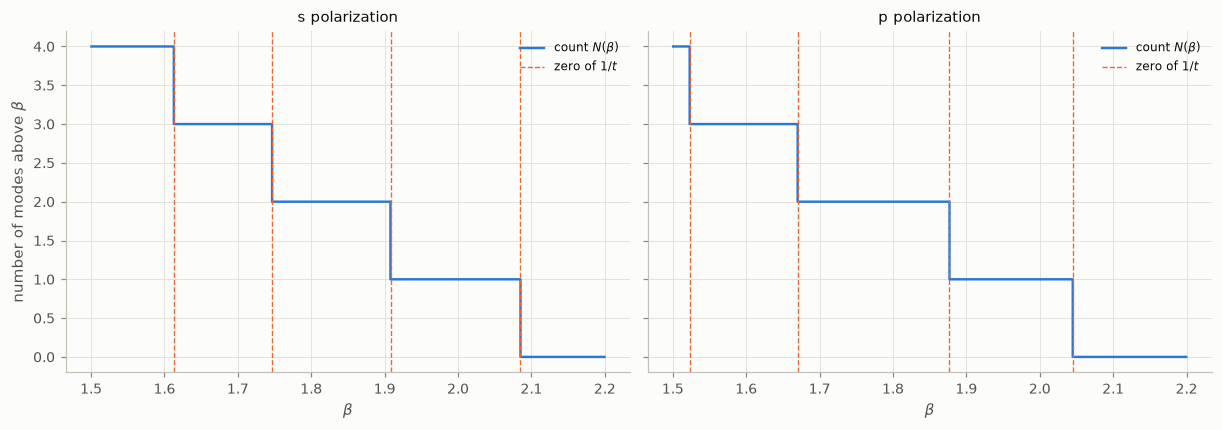

PASS  bisection on the count against the zeros of 1/t, 8 modes: largest difference in beta: got 6.66134e-16, target 0, |diff| 6.66e-16 <= 1e-13
count unchanged when the sublayers are made 2.5 times thinner: True
zeros of the left-decaying solution equal the count at 23 values of beta: True


In [4]:
def count1(beta, pol, stack=wg, safety=0.5):
    ms = lambda e: ml.modes_scalar(e, beta, pol)
    return ml.count_modes(ms(stack.eps_a), [(ms(e), d) for e, d in stack.layers], ms(stack.eps_b), safety=safety)


fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.8), sharey=True)
for ax, pol in zip(axes, "sp"):
    N = np.array([count1(b, pol) for b in grid])
    ax.step(grid, N, where="mid", color=CAT[0], label=r"count $N(\beta)$")
    for i, b in enumerate(roots1[pol]):
        ax.axvline(b, color=CAT[1], lw=0.9, ls="--", label="zero of $1/t$" if i == 0 else None)
    ax.set(xlabel=r"$\beta$", title=f"{pol} polarization")
    ax.legend(loc="upper right", fontsize=8)
    # the count must drop by one exactly at each root and nowhere else
    jumps = grid[:-1][np.diff(N) != 0]
    assert len(jumps) == len(roots1[pol]) and np.all(np.diff(N) <= 0)
    assert np.all(np.abs(np.sort(jumps) - np.sort(roots1[pol])) < 2 * (grid[1] - grid[0]))
axes[0].set_ylabel("number of modes above $\\beta$")
plt.show()

worst, total = 0.0, 0
for pol in "sp":
    found = ml.slice_modes(lambda b: count1(b, pol), B_LO, B_HI, tol=1e-15)
    assert [m for _, m in found] == [1] * len(roots1[pol])
    worst = max(worst, max(abs(b - r) for (b, _), r in zip(found, roots1[pol])))
    total += len(found)
check(f"bisection on the count against the zeros of 1/t, {total} modes: largest difference in beta", worst, 1e-13)
same = all(count1(b, pol, safety=0.5) == count1(b, pol, safety=0.2) for pol in "sp" for b in grid[::40])
print("count unchanged when the sublayers are made 2.5 times thinner:", same)
assert same

# Sturm: the number of modes above beta is the number of zeros of the solution that decays to the left
z = np.linspace(0, wg.interfaces()[-1], 4001)
ok = True
for b in np.linspace(B_LO, B_HI, 23):
    ea, ls, eb = wg.params(b, "s")
    u, v = 1.0, (ea / 1j).real                        # decaying toward z -> -infinity: u = exp(kappa z), v = kappa u
    us = []
    zi = wg.interfaces()
    for j, (q, eta, d) in enumerate(ls):
        s = z[(z >= zi[j]) & (z <= zi[j + 1])] - zi[j]
        us.append((np.cos(q * s) * u + np.sin(q * s) / eta * v).real)
        A, B, C, D = ml.T_layer(q, eta, d)
        u, v = (A * u + B * v).real, (C * u + D * v).real
    uu = np.concatenate(us)
    zeros = int(np.sum(uu[:-1] * uu[1:] < 0))
    kb = (eb / 1j).real                               # in the substrate u = u cosh(kb s) + (v/kb) sinh(kb s): one more zero if v/(kb u) < -1
    zeros += int(v / (kb * u) < -1)
    ok &= zeros == count1(b, "s")
print("zeros of the left-decaying solution equal the count at 23 values of beta:", ok)
assert ok

## 3. Two guides and a thick gap

Two identical cores of index 2.0 and thickness $0.4\lambda_0$ in glass, separated by a gap $g$ of glass. The even and odd supermodes are split by an amount proportional to $e^{-\kappa g}$. Three things are compared as the gap grows: the number of fundamental modes that a sign search of $1/t$ on a fixed grid of 4000 points finds, the splitting from bisection on the count, and the exponential law.

32 gaps, 10.4 s


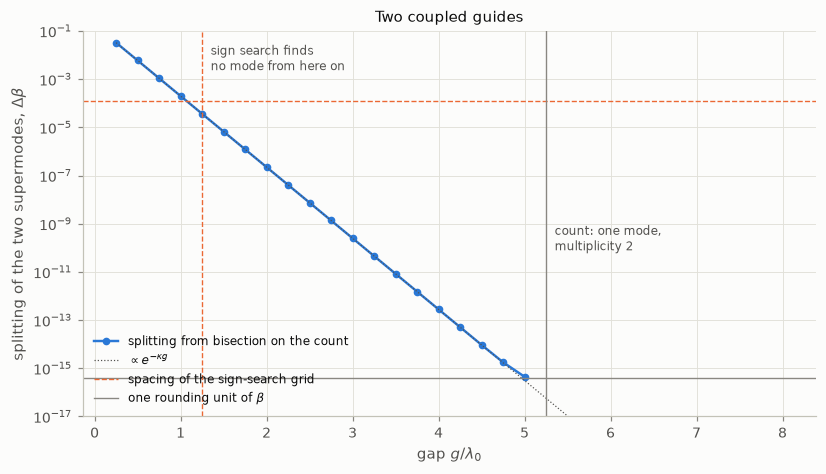

PASS  slope of ln(splitting) against the gap, in units of -kappa: got 0.999995, target 1, |diff| 5.36e-06 <= 2e-02
sign search on the grid: two modes up to g = 1.00, then [np.int64(0)] modes
count: two separate modes up to g = 5.00 (splitting 4.4e-16), multiplicity two from g = 5.25


In [5]:
coupler = lambda g: ml.Stack(2.25, [(4.0, 0.4), (2.25, g), (4.0, 0.4)], 2.25)
C_LO, C_HI = 1.5005, 1.9995
cgrid = np.linspace(C_LO, C_HI, 4001)
gaps = np.arange(0.25, 8.01, 0.25)
split, mult, n_sign = [], [], []
t0 = time.time()
for g in gaps:
    stc = coupler(g)
    found = ml.slice_modes(lambda b: count1(b, "s", stc), C_LO, C_HI, tol=1e-16)
    top = [f for f in found if f[0] > 1.8]            # the pair of fundamental supermodes
    mult.append(top[0][1])
    split.append(top[0][0] - top[1][0] if top[0][1] == 1 else 0.0)
    n_sign.append(sum(r > 1.8 for r in roots_by_sign(lambda b: secular1(b, "s", stc).real, cgrid)))
    assert sum(m for _, m in top) == 2
split, mult, n_sign = np.array(split), np.array(mult), np.array(n_sign)
print(f"{len(gaps)} gaps, {time.time() - t0:.1f} s")
beta_pair = ml.slice_modes(lambda b: count1(b, "s", coupler(8.0)), C_LO, C_HI, tol=1e-16)[0][0]
kap_g = abs(ml.kz(2.25, beta_pair).imag)

fig, ax = plt.subplots(figsize=(7.4, 4.2))
res = split > 0
ax.semilogy(gaps[res], split[res], "o-", ms=4, color=CAT[0], label="splitting from bisection on the count")
ref_i = np.argmin(np.abs(gaps - 2.0))
ax.semilogy(gaps, split[ref_i] * np.exp(-kap_g * (gaps - gaps[ref_i])), color=INK2, lw=0.8, ls=":", label=r"$\propto e^{-\kappa g}$")
ax.axhline(cgrid[1] - cgrid[0], color=CAT[1], lw=0.9, ls="--", label="spacing of the sign-search grid")
ax.axhline(EPS * beta_pair, color=MUTED, lw=0.9, label=r"one rounding unit of $\beta$")
g_lost = gaps[np.argmax(n_sign < 2)]
ax.axvline(g_lost, color=CAT[1], lw=0.9, ls="--")
ax.text(g_lost + 0.1, 3e-2, "sign search finds\nno mode from here on", color=INK2, fontsize=8, va="top")
g_merge = gaps[np.argmax(mult == 2)]
ax.axvline(g_merge, color=MUTED, lw=0.9)
ax.text(g_merge + 0.1, 1e-9, "count: one mode,\nmultiplicity 2", color=INK2, fontsize=8, va="top")
ax.set(xlabel=r"gap $g/\lambda_0$", ylabel=r"splitting of the two supermodes, $\Delta\beta$", ylim=(1e-17, 1e-1),
       title="Two coupled guides")
ax.legend(loc="lower left", fontsize=8)
plt.show()

fit = (split > 1e-13) & (split < 1e-3)
slope = np.polyfit(gaps[fit], np.log(split[fit]), 1)[0]
check("slope of ln(splitting) against the gap, in units of -kappa", slope / (-kap_g), 0.02, 1.0)
print(f"sign search on the grid: two modes up to g = {gaps[n_sign == 2].max():.2f}, then {sorted(set(n_sign[n_sign < 2]))} modes")
print(f"count: two separate modes up to g = {gaps[mult == 1].max():.2f} (splitting {split[mult == 1][-1]:.1e}), multiplicity two from g = {g_merge:.2f}")
assert split[mult == 1][-1] < 1e-14 and gaps[mult == 1].max() > gaps[n_sign == 2].max() + 2

Past the gap marked by the dashed line the secular function touches zero without crossing it on the scale of the grid: both modes are there and the search returns none, with nothing to indicate that anything was missed. A finer grid moves the line to the right and no further than that. The count cannot miss them, because it never looks for a sign change: it says how many modes lie in an interval, and bisection narrows the interval. The splitting follows the exponential law until it is one rounding unit of $\beta$, and from there on the answer is one mode counted twice, which is the correct statement in double precision.

This is not an $\Omega d$ failure of the transfer matrix, whose secular function is accurate here. It is the reason to want the count, which exists only in the stable variants: the stiffness matrix of a thick evanescent layer is finite, and the count follows from its pivots.

## 4. Two channels: Dunkin's cancellation

The waveguide now has a birefringent layer: air, a core of index 2.0 and thickness $0.8\lambda_0$, a buffer of a negative uniaxial material ($n_o=1.658$, $n_e=1.486$, the indices of calcite) with its axis in the plane of the layers at $60^\circ$ to the direction of propagation, and a substrate of index 1.5. For $\beta$ between 1.66 and 2 both waves of the buffer are evanescent, with different decay rates, and the modes are hybrid: neither s nor p.

In the transfer-matrix method the condition for a mode is that some outgoing field in the substrate arrives in the air without the growing waves: $\det K_{11}=0$ with $K=F_a^{-1}NF_b$ as in notebook 02. The entries of $K_{11}$ are of size $e^{\kappa_{\max}D}$ and their $2\times2$ determinant is of size $e^{(\kappa_1+\kappa_2)D}$, smaller than the products it is made of by $e^{(\kappa_{\max}-\kappa_{\min})D}$. In Plücker coordinates $\det K_{11}$ is the first of the six coordinates of the plane, in the mode basis of the air, and it is carried through the buffer by its own exponential $e^{(\kappa_1+\kappa_2)D}$.

buffer at beta = 1.85: decay rates 5.157 and 6.426 per wavelength, difference 1.269; difference x D = ln(1/eps) at D = 28.4 wavelengths


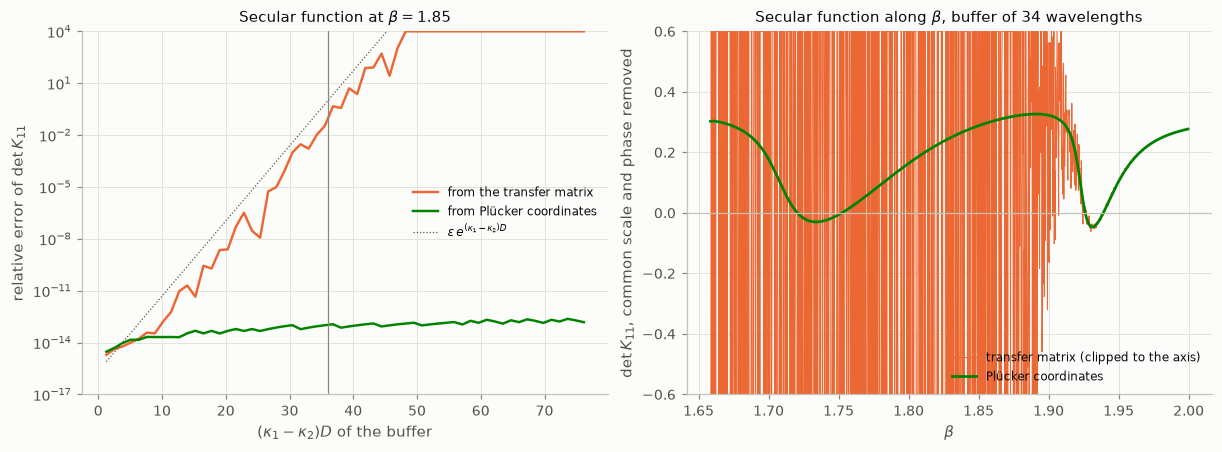

PASS  exponent of the transfer-matrix error of the secular function, d ln(error) / d((kappa_1 - kappa_2) D): got 1.0259, target 1, |diff| 2.59e-02 <= 1e-01
PASS  (kappa_1 - kappa_2) D at which that error first exceeds 0.1: got 36.8148, target 36.0437, |diff| 7.71e-01 <= 5e+00
PASS  largest error of the secular function from Plücker coordinates, D up to 60 wavelengths: got 2.34981e-13, target 0, |diff| 2.35e-13 <= 1e-11
PASS  Plücker secular function along beta: largest |Im| / |.| after removing a constant phase: got 6.61568e-13, target 0, |diff| 6.62e-13 <= 1e-08
sign changes on the grid at D = 34: 4 from Plücker coordinates, 429 from the transfer matrix


In [6]:
n_core, d_core, n_o, n_e, phi_c, n_sub = 2.0, 0.8, 1.658, 1.486, np.radians(60), 1.5
eps_u = ml.uniaxial(n_o ** 2, n_e ** 2, np.pi / 2, phi_c)
H_LO, H_HI = 1.6585, 1.9995


def build(beta, D, kind="single"):
    air, core, buf = ml.modes_iso4(1.0, beta), ml.modes_iso4(n_core ** 2, beta), ml.modes_aniso(eps_u, beta)
    if kind == "single":
        return air, [(core, d_core), (buf, D)], ml.modes_iso4(n_sub ** 2, beta)
    if kind == "isotropic":                           # the buffer replaced by an isotropic layer, for a check
        return air, [(core, d_core), (ml.modes_iso4(n_o ** 2, beta), D)], ml.modes_iso4(n_sub ** 2, beta)
    return air, [(core, d_core), (buf, D), (core, d_core)], air                     # two cores, buffer between


def generators(beta, D, kind="single"):
    Gc, Gb = ml.berreman_G(n_core ** 2 * np.eye(3), beta), ml.berreman_G(eps_u, beta)
    return [(Gc, d_core), (Gb, D)] if kind == "single" else [(Gc, d_core), (Gb, D), (Gc, d_core)]


def secular_T(beta, D, kind="single"):
    """det K11 from the product of transfer matrices."""
    Ma, L, Mb = build(beta, D, kind)
    P = np.eye(4, dtype=complex)
    for M, d in L:
        P = P @ M.T(-d)
    return np.linalg.det(np.linalg.solve(Ma.F, P @ Mb.F)[:2, :2])


def secular_P(beta, D, kind="single"):
    """(p01, logscale): det K11 = p01 exp(logscale), from Plucker coordinates."""
    Ma, L, Mb = build(beta, D, kind)
    _, pm, ls = ml.compound_R(Ma, L, Mb)
    return pm[0], ls


def secular_ref(beta, D, kind="single", dps=None):
    """det K11 in multiprecision."""
    Ma, L, Mb = build(beta, D, kind)
    dps = dps or int(80 + 2 * 14.0 * D / np.log(10))
    with mp.workdps(dps):
        tomp = lambda X: mp.matrix([[mp.mpc(complex(x)) for x in row] for row in np.asarray(X)])
        P = mp.eye(4)
        for G, d in generators(beta, D, kind):
            P = P * mp.expm(tomp(G) * (-mp.mpf(d)), method="taylor")
        K = mp.inverse(tomp(Ma.F)) * (P * tomp(Mb.F))
        return K[0, 0] * K[1, 1] - K[0, 1] * K[1, 0]


beta_t = 1.85
buf = ml.modes_aniso(eps_u, beta_t)
dkap = abs(buf.qp[0].imag - buf.qp[1].imag)
print(f"buffer at beta = {beta_t}: decay rates {buf.qp[0].imag:.3f} and {buf.qp[1].imag:.3f} per wavelength, difference {dkap:.3f}; "
      f"difference x D = ln(1/eps) at D = {np.log(1 / EPS) / dkap:.1f} wavelengths")

Ds = np.arange(1.0, 60.01, 1.0)
eT, eP = [], []
for D in Ds:
    ref = secular_ref(beta_t, D)
    p01, ls = secular_P(beta_t, D)
    with mp.workdps(60):
        eP.append(float(abs(mp.mpc(complex(p01)) * mp.exp(mp.mpf(float(ls))) - ref) / abs(ref)))
    eT.append(ml.relerr(secular_T(beta_t, D), ref))
eT, eP = np.array(eT), np.array(eP)

D_show = 34.0
bgrid = np.linspace(H_LO, H_HI, 1201)
fP = np.array([secular_P(b, D_show) for b in bgrid])
fT = np.array([secular_T(b, D_show) for b in bgrid]) * np.exp(-fP[:, 1].real)
phase = fP[len(bgrid) // 2, 0] / abs(fP[len(bgrid) // 2, 0])
gP, gT = (fP[:, 0] / phase), fT / phase

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0))
ax = axes[0]
ax.semilogy(dkap * Ds, clip(eT), color=CAT[1], label="from the transfer matrix")
ax.semilogy(dkap * Ds, clip(eP), color=CAT[5], label="from Plücker coordinates")
ax.semilogy(dkap * Ds, EPS * np.exp(dkap * Ds), color=INK2, lw=0.8, ls=":", label=r"$\epsilon\,e^{(\kappa_1-\kappa_2)D}$")
ax.axvline(np.log(1 / EPS), color=MUTED, lw=0.8)
ax.set(xlabel=r"$(\kappa_1-\kappa_2)D$ of the buffer", ylabel=r"relative error of $\det K_{11}$", ylim=(1e-17, 1e4),
       title=r"Secular function at $\beta=1.85$")
ax.legend(loc="center right", fontsize=8)
ax = axes[1]
ax.plot(bgrid, np.clip(gT.real, -0.6, 0.6), color=CAT[1], lw=0.7, label="transfer matrix (clipped to the axis)")
ax.plot(bgrid, gP.real, color=CAT[5], lw=1.8, label="Plücker coordinates")
ax.axhline(0, color=AXIS, lw=0.8)
ax.set(xlabel=r"$\beta$", ylabel=r"$\det K_{11}$, common scale and phase removed", ylim=(-0.6, 0.6),
       title=f"Secular function along $\\beta$, buffer of {D_show:.0f} wavelengths")
ax.legend(loc="lower right", fontsize=8)
plt.show()

sel = (eT > 1e-12) & (eT < 1e-2)
check("exponent of the transfer-matrix error of the secular function, d ln(error) / d((kappa_1 - kappa_2) D)", np.polyfit(dkap * Ds[sel], np.log(eT[sel]), 1)[0], 0.15, 1.0)
check("(kappa_1 - kappa_2) D at which that error first exceeds 0.1", dkap * Ds[np.argmax(eT > 0.1)], 5.0, np.log(1 / EPS))
check("largest error of the secular function from Plücker coordinates, D up to 60 wavelengths", eP.max(), 1e-11)
check("Plücker secular function along beta: largest |Im| / |.| after removing a constant phase", np.max(np.abs(gP.imag) / np.abs(gP)), 1e-8)
sT = int(np.sum(gT.real[:-1] * gT.real[1:] < 0))
sP = int(np.sum(gP.real[:-1] * gP.real[1:] < 0))
print(f"sign changes on the grid at D = {D_show:.0f}: {sP} from Plücker coordinates, {sT} from the transfer matrix")
assert sT > 5 * sP

The left panel is the law of notebook 02 again, now for the quantity that mode solvers use, and the right panel is what a root search is given at a buffer of 34 wavelengths: from the transfer matrix, noise, with the number of sign changes printed above; from Plücker coordinates, a smooth curve with one zero for each mode.

## 5. Two channels: counting hybrid modes

For the count, the form of section 2 needs "coordinates" $U$ and "momenta" $V$ in which the kinetic part is positive. With $\varepsilon_{xz}=\varepsilon_{yz}=0$, which covers an axis in the plane of the layers, the choice $U=(iH_y,\,E_y)$, $V=(-E_x,\,-iH_x)$ makes Maxwell's equations a real Hamiltonian system $U'=k_0(BV+DU)$, $V'=-k_0(D^TV+CU)$ with $B=\operatorname{diag}(\varepsilon_{xx},1)>0$, and $\beta^2$ enters $C$ with a definite sign, so the number of modes above $\beta$ is again the number of negative directions of a quadratic form whose boundary terms are $U^TV$. The $2\times2$ blocks of the stiffness matrices in these variables should come out real and symmetric, which `count_modes` monitors.

Checks: with the buffer replaced by an isotropic layer the count must be the sum of the one-channel counts for s and p; for the anisotropic buffer the count must drop exactly at the zeros of the Plücker secular function; and the multiprecision $\det K_{11}$ must change sign across every mode found.

isotropic buffer: two-channel count equals the s count plus the p count at 301 values of beta: True
PASS  stiffness pivots in the real variables: largest relative departure from a Hermitian matrix: got 1.75414e-13, target 0, |diff| 1.75e-13 <= 1e-09
buffer of 34 wavelengths: 4 hybrid modes, beta = [1.93902341 1.92613283 1.75233524 1.72062805]
PASS  bisection on the count against the zeros of the Plücker secular function: largest difference in beta: got 4.44089e-16, target 0, |diff| 4.44e-16 <= 1e-12
count unchanged when the sublayers are made 2.5 times thinner: True


PASS  multiprecision det K11 on the two sides of each mode, 1e-10 away: largest of Re(ratio) and |Im(ratio)| (negative means a sign change): got 4.98957e-25, target -1, |diff| 1.00e+00 <= 1e+00


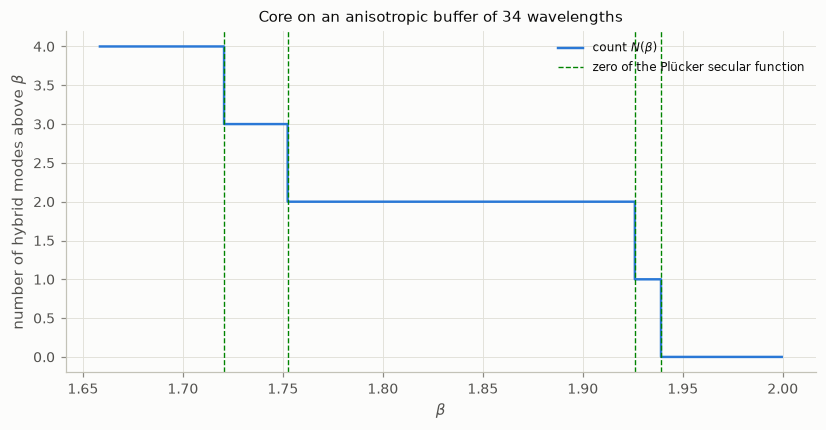

In [7]:
Z = ml.Z_REAL


def count2(beta, D, kind="single", safety=0.5, full=False):
    Ma, L, Mb = build(beta, D, kind)
    out = ml.count_modes(ml.transformed(Ma, Z), [(ml.transformed(M, Z), d) for M, d in L], ml.transformed(Mb, Z), safety=safety, return_pivots=True)
    return out if full else out[0]


# isotropic limit against the one-channel counts
D_iso = 1.3
st_iso = ml.Stack(1.0, [(n_core ** 2, d_core), (n_o ** 2, D_iso)], n_sub ** 2)
bb = np.linspace(H_LO, H_HI, 301)
ok = all(count2(b, D_iso, "isotropic") == count1(b, "s", st_iso) + count1(b, "p", st_iso) for b in bb)
print("isotropic buffer: two-channel count equals the s count plus the p count at 301 values of beta:", ok)
assert ok

D_h = 34.0
N_h = np.array([count2(b, D_h) for b in bgrid])
asym = max(count2(b, D_h, full=True)[2] for b in bgrid[::50])
check("stiffness pivots in the real variables: largest relative departure from a Hermitian matrix", asym, 1e-9)
zeros_P = sorted(roots_by_sign(lambda b: (secular_P(b, D_h)[0] / phase).real, bgrid), reverse=True)
modes_h = ml.slice_modes(lambda b: count2(b, D_h), H_LO, H_HI, tol=1e-15)
print(f"buffer of {D_h:.0f} wavelengths: {len(modes_h)} hybrid modes, beta = {np.round([b for b, _ in modes_h], 10)}")
assert [m for _, m in modes_h] == [1] * len(zeros_P)
check("bisection on the count against the zeros of the Plücker secular function: largest difference in beta", max(abs(b - z_) for (b, _), z_ in zip(modes_h, zeros_P)), 1e-12)
same = all(count2(b, D_h, safety=0.5) == count2(b, D_h, safety=0.2) for b in bgrid[::20])
print("count unchanged when the sublayers are made 2.5 times thinner:", same)
assert same

worst = 0.0
for b, _ in modes_h:
    r = complex(secular_ref(b * (1 + 1e-10), D_h) / secular_ref(b * (1 - 1e-10), D_h))
    worst = max(worst, r.real, abs(r.imag))
check("multiprecision det K11 on the two sides of each mode, 1e-10 away: largest of Re(ratio) and |Im(ratio)| (negative means a sign change)", worst, 1.0, -1.0)

fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.step(bgrid, N_h, where="mid", color=CAT[0], label=r"count $N(\beta)$")
for i, z_ in enumerate(zeros_P):
    ax.axvline(z_, color=CAT[5], lw=0.9, ls="--", label="zero of the Plücker secular function" if i == 0 else None)
ax.set(xlabel=r"$\beta$", ylabel="number of hybrid modes above $\\beta$", title=f"Core on an anisotropic buffer of {D_h:.0f} wavelengths")
ax.legend(loc="upper right", fontsize=8)
plt.show()

### Two cores with the anisotropic layer between them

The last structure combines the two difficulties: air, core, the uniaxial layer of thickness $D$, a second identical core, air. The modes come in pairs, and the secular determinant from the transfer matrix is unusable beyond a moderate $D$. The count gives the pairs, their splittings while they can be resolved, and their multiplicity afterward.

With one evanescent wave in the gap the splitting of a pair is a single exponential, as in section 3. Here the gap has two, with decay rates $\kappa_o<\kappa_e$, and the simplest guess is a sum of two exponentials,

$$\Delta\beta(D)=A\,e^{-\kappa_eD}-B\,e^{-\kappa_oD}.$$

The cell fits this to the computed splitting of the pair with the largest $\beta$. The count gives only the magnitude of the splitting, so the sign is assigned: one sign up to the thickness where the magnitude is smallest and the other beyond it.

41 thicknesses, 14.2 s
first pair: beta = 1.939023412142; decay rates of the two waves of the layer there: 6.3172 and 7.3454 per wavelength


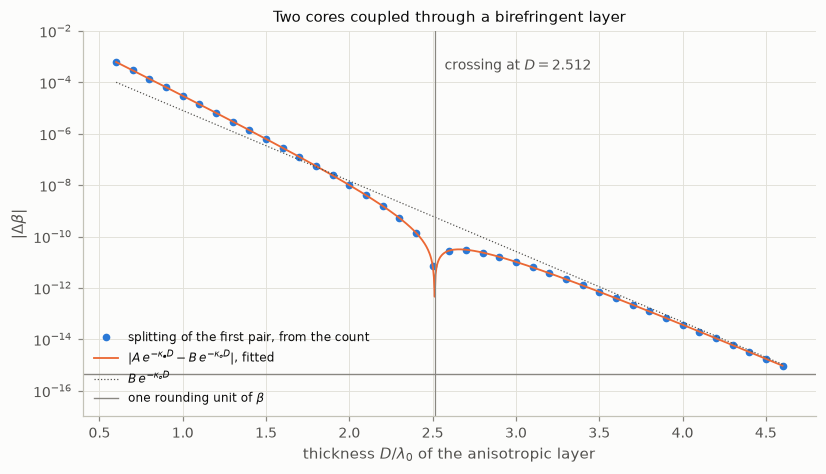

fit: A = 5.8940e-02, B = 4.4544e-03; the two terms cancel at D = 2.5116
PASS  largest residual of the straight-line fit, relative to the largest ordinate: got 4.50847e-05, target 0, |diff| 4.51e-05 <= 1e-02
splitting at the fitted crossing: 2.13e-14; at the neighboring grid thicknesses 1.41e-10 and 2.85e-11
modes counted with multiplicity: 8 at every thickness

thick layers:   D     modes (beta, multiplicity), the three largest beta
              6.0     (1.9390234121416, 2)  (1.9261328291269, 2)  (1.7523352402375, 1)
             10.0     (1.9390234121416, 2)  (1.9261328291269, 2)  (1.7523352402370, 2)
             30.0     (1.9390234121416, 2)  (1.9261328291269, 2)  (1.7523352402370, 2)
             60.0     (1.9390234121416, 2)  (1.9261328291269, 2)  (1.7523352402370, 2)
PASS  D = 2: multiprecision det K11 changes sign across each of the four largest-beta modes (as above): got 2.94642e-27, target -1, |diff| 1.00e+00 <= 1e+00


In [8]:
Dc = np.round(np.arange(0.6, 4.61, 0.1), 2)
split_h, total_h = [], []
t0 = time.time()
for D in Dc:
    found = ml.slice_modes(lambda b: count2(b, D, "coupler"), H_LO, H_HI, tol=1e-16)
    total_h.append(sum(m for _, m in found))
    split_h.append(found[0][0] - found[1][0] if found[0][1] == 1 else 0.0)
split_h = np.array(split_h)
print(f"{len(Dc)} thicknesses, {time.time() - t0:.1f} s")
beta_1 = ml.slice_modes(lambda b: count2(b, 30.0, "coupler"), H_LO, H_HI, tol=1e-16)[0][0]
kap_o, kap_e = sorted(ml.modes_aniso(eps_u, beta_1).qp.imag)
print(f"first pair: beta = {beta_1:.12f}; decay rates of the two waves of the layer there: {kap_o:.4f} and {kap_e:.4f} per wavelength")

dips = [i for i in range(1, len(Dc) - 1) if split_h[i] < split_h[i - 1] and split_h[i] < split_h[i + 1]]
assert len(dips) == 1, "expected one interior minimum of the splitting"
i_min = dips[0]
sign = np.where(np.arange(len(Dc)) <= i_min, 1.0, -1.0)
x, y = np.exp(-(kap_e - kap_o) * Dc), sign * split_h * np.exp(kap_o * Dc)       # the model is the straight line y = A x - B
use = (split_h > 3e-13) & (np.arange(len(Dc)) != i_min)
A_fit, mB_fit = np.polyfit(x[use], y[use], 1)
B_fit = -mB_fit
D_cross = np.log(A_fit / B_fit) / (kap_e - kap_o)
model = np.abs(A_fit * np.exp(-kap_e * Dc) - B_fit * np.exp(-kap_o * Dc))
resid = np.abs(A_fit * x[use] - B_fit - y[use]).max() / np.abs(y[use]).max()
found_x = ml.slice_modes(lambda b: count2(b, D_cross, "coupler"), H_LO, H_HI, tol=1e-16)
split_x = found_x[0][0] - found_x[1][0] if found_x[0][1] == 1 else 0.0

fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.semilogy(Dc, np.maximum(split_h, 1e-17), "o", ms=4, color=CAT[0], label="splitting of the first pair, from the count")
Df = np.linspace(Dc[0], Dc[-1], 800)
ax.semilogy(Df, np.abs(A_fit * np.exp(-kap_e * Df) - B_fit * np.exp(-kap_o * Df)), color=CAT[1], lw=1.2, label=r"$|A\,e^{-\kappa_eD}-B\,e^{-\kappa_oD}|$, fitted")
ax.semilogy(Df, B_fit * np.exp(-kap_o * Df), color=INK2, lw=0.8, ls=":", label=r"$B\,e^{-\kappa_oD}$")
ax.axhline(EPS * beta_1, color=MUTED, lw=0.9, label=r"one rounding unit of $\beta$")
ax.axvline(D_cross, color=MUTED, lw=0.8)
ax.text(D_cross + 0.06, 3e-4, f"crossing at $D={D_cross:.3f}$", color=INK2, fontsize=9)
ax.set(xlabel=r"thickness $D/\lambda_0$ of the anisotropic layer", ylabel=r"$|\Delta\beta|$", ylim=(1e-17, 1e-2),
       title="Two cores coupled through a birefringent layer")
ax.legend(loc="lower left", fontsize=8)
plt.show()

print(f"fit: A = {A_fit:.4e}, B = {B_fit:.4e}; the two terms cancel at D = {D_cross:.4f}")
check("largest residual of the straight-line fit, relative to the largest ordinate", resid, 0.01)
assert A_fit > 0 and B_fit > 0, "the two exponentials should enter with opposite signs"
print(f"splitting at the fitted crossing: {split_x:.2e}; at the neighboring grid thicknesses {split_h[i_min - 1]:.2e} and {split_h[i_min + 1]:.2e}")
assert split_x < 0.2 * min(split_h[i_min - 1], split_h[i_min + 1])
assert len(set(total_h)) == 1
print(f"modes counted with multiplicity: {total_h[0]} at every thickness")

print()
print("thick layers:   D     modes (beta, multiplicity), the three largest beta")
for D in (6.0, 10.0, 30.0, 60.0):
    found = ml.slice_modes(lambda b: count2(b, D, "coupler"), H_LO, H_HI, tol=1e-16)
    assert sum(m for _, m in found) == total_h[0] and found[0][1] == 2
    print(f"            {D:5.1f}     " + "  ".join(f"({b:.13f}, {m})" for b, m in found[:3]))

# the resolved pairs at D = 2 against the multiprecision determinant
found = ml.slice_modes(lambda b: count2(b, 2.0, "coupler"), H_LO, H_HI, tol=1e-16)
worst = 0.0
for b, m in found[:4]:
    r = complex(secular_ref(b * (1 + 1e-11), 2.0, "coupler") / secular_ref(b * (1 - 1e-11), 2.0, "coupler"))
    worst = max(worst, r.real, abs(r.imag))
check("D = 2: multiprecision det K11 changes sign across each of the four largest-beta modes (as above)", worst, 1.0, -1.0)

The two exponentials enter with opposite signs, and at one thickness they cancel: the even and the odd hybrid supermode cross. Below that thickness the wave of the layer that decays faster carries more of the coupling, above it the slower one takes over, and far above it the splitting is the single exponential $B\,e^{-\kappa_oD}$ until it reaches the rounding of $\beta$. Nothing forbids the crossing, since the two supermodes have opposite parity under the reflection that exchanges the cores. At the thickness where the fit puts it, the count finds a splitting far below that of the neighboring thicknesses.

This was not looked for; it came out of having the splitting to the last bit at every thickness. A search for sign changes of a secular function would report a single mode there, or none.

## Summary

- One channel: the secular function $1/t$ from the rescaled vector is accurate for any thickness, and mode finding with the transfer matrix is sound. Its practical weakness is the search, not the function: nearly degenerate modes give no sign change on a grid.
- Two channels: the secular function from the transfer matrix is a determinant with Dunkin's cancellation, wrong by $\epsilon\,e^{(\kappa_1-\kappa_2)D}$ and unusable from $(\kappa_1-\kappa_2)D\approx36$. Plücker coordinates carry the same determinant exactly.
- Counting replaces searching. The number of modes above $\beta$ is the number of negative pivots of the assembled stiffness matrix, with layers cut thin enough to have no modes of their own. It is an integer computed from decaying exponentials, it gives multiplicities, and bisection on it found every mode in every structure here to the last bits of $\beta$.
- With a birefringent layer between two guides the splitting of a pair fits $A\,e^{-\kappa_eD}-B\,e^{-\kappa_oD}$ with $A,B>0$ to the residual printed, and vanishes at one thickness.
- The count is also the cleanest use of the charts of notebook 03: the stiffness matrix is exact for thick layers, which is where it is needed, and its singular set, which was a nuisance for reflection, is here the thing being counted.

## Caveats and open ends

- Lossless dielectrics only. With metals the quadratic form is indefinite in p polarization and the count no longer equals the number of modes; with absorption or leakage the modes are complex and a count on the real axis does not apply. Counting complex modes (by the argument principle on a stable secular function) was not attempted.
- The two-channel count was set up for $\varepsilon_{xz}=\varepsilon_{yz}=0$. For a general orientation of the axis the system is Hermitian but not real, and $\beta$ enters linearly as well as quadratically; the form of the count for that case was not worked out.
- The rule for cutting layers (half a wavelength along $z$ of the fastest-oscillating wave, times a safety factor) is exact for uncoupled channels. For a coupled anisotropic layer it is a plausible bound that was checked by refining the sublayers, not proved, and in the structures here the anisotropic layer was evanescent for all $\beta$ considered, so that case was never exercised with propagating waves.
- The statement that the count is a Maslov index is the standard reading of the Sturm and Morse index theorems; nothing here depends on it and it was not computed independently as a winding number.
- The two-exponential form of the splitting is a fit to the pair with the largest $\beta$ over one range of thickness, with the sign of the splitting assigned by hand on the two sides of its minimum. That the two waves of the layer contribute with opposite signs was not derived, the parity of the two supermodes was not computed, and the crossing was located by the fit and confirmed only by the smallness of the splitting there.
- Frequency was fixed and $\beta$ was the unknown. Counting in frequency at fixed $k_x$ leads to a form with an indefinite weight when some layers are evanescent and was not considered.